# Airbnb Amsterdam – Price Regression Models

This notebook trains and evaluates regression models that predict the nightly listing price from the
processed tables written by `01_preprocessing.ipynb`.

**Inputs** (created by the preprocessing notebook, in `../processed/`)

- `df_train_processed.parquet`, `df_test_processed.parquet` – numeric feature tables including the target `price`
- `selected_features.json` – the feature shortlist produced by the training-data-only feature-selection report

**Outputs** (written to `../results/` and `../images/`)

- `cv_results.csv`, `test_results.csv`, `best_params.json`, figures

**Validation protocol**

1. All hyperparameters are chosen by 5-fold cross-validation on the **training set only**.
2. The test set is used once per fitted model, after model selection, for the final evaluation.
3. Models are trained on `log1p(price)` and evaluated on the **original price scale** (R², MAE, RMSE).
4. Cross-validation scores (model selection) and test scores (final evaluation) are different quantities and are reported in separate tables.

## 1. Setup

In [1]:
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
N_FOLDS = 5
TARGET = "price"
PRICE_CAP = 30_000          # see section 3
LEAKY_OR_ID_COLUMNS = ["id", "host_id", "estimated_revenue_l365d"]

# Works when the notebook is opened from `notebooks/` or from the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
IMAGES_DIR = PROJECT_ROOT / "images"
RESULTS_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

CV = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print("Project root:", PROJECT_ROOT)

Project root: airbnb-price-prediction


## 2. Load processed data and the selected-feature shortlist

In [2]:
required = {
    "training table": PROCESSED_DIR / "df_train_processed.parquet",
    "test table": PROCESSED_DIR / "df_test_processed.parquet",
    "feature shortlist": PROCESSED_DIR / "selected_features.json",
}
for label, path in required.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {label}: {path}. Run notebooks/01_preprocessing.ipynb first "
            f"(it creates every file in {PROCESSED_DIR})."
        )

df_train = pd.read_parquet(required["training table"])
df_test = pd.read_parquet(required["test table"])
shortlist = json.loads(required["feature shortlist"].read_text())
selected_features = shortlist["selected_features"]

print("Train:", df_train.shape, "| Test:", df_test.shape)
print("Selected features loaded:", len(selected_features))

Train: (4699, 2269) | Test: (1175, 2269)
Selected features loaded: 35


In [3]:
# Consistency checks on the data handed over by the preprocessing notebook.
assert TARGET in df_train.columns and TARGET in df_test.columns
assert list(df_train.columns) == list(df_test.columns), "Train/test columns differ"
assert not set(LEAKY_OR_ID_COLUMNS) & set(df_train.columns), "Leaky or identifier column present"
assert not df_train.isna().any().any() and not df_test.isna().any().any(), "Unexpected missing values"

feature_columns = [c for c in df_train.columns if c != TARGET]
missing = [f for f in selected_features if f not in feature_columns]
assert not missing, f"Selected features not found in the processed training data: {missing[:5]}"
assert TARGET not in selected_features
assert len(set(selected_features)) == len(selected_features), "Duplicate selected features"
print(f"{len(feature_columns)} candidate predictors; all {len(selected_features)} selected features exist in the data.")

2268 candidate predictors; all 35 selected features exist in the data.


In [4]:
# Some libraries (LightGBM, XGBoost) reject characters such as spaces or brackets in column names.
# Rename once, consistently for train, test and the shortlist, and keep the mapping.
def sanitize(name):
    return re.sub(r"[^0-9a-zA-Z_]+", "_", name).strip("_")

mapping, used = {}, set()
for col in feature_columns:
    new = sanitize(col) or "feature"
    base, k = new, 1
    while new in used:
        k += 1
        new = f"{base}_{k}"
    used.add(new)
    mapping[col] = new
assert len(set(mapping.values())) == len(mapping)

X_train_full = df_train[feature_columns].rename(columns=mapping)
X_test_full = df_test[feature_columns].rename(columns=mapping)
y_train_raw = df_train[TARGET].astype(float)
y_test_raw = df_test[TARGET].astype(float)
selected_cols = [mapping[f] for f in selected_features]

## 3. Extreme prices and the evaluation set

The target contains a few listings with extreme nightly prices. Because R² is based on squared errors, a handful of such rows can dominate every metric.

- **Training set:** listings with `price >= PRICE_CAP` are excluded from model fitting and cross-validation (training-set cleaning).
- **Test set:** the test set is **not** filtered for the primary evaluation. Removing test rows by their target value would make the evaluation optimistic, because it excludes the cases the model would find hardest. For comparison with an earlier version of this project, a second column reports the same models on the test rows below the cap.

In [5]:
print("Training price quantiles:")
print(y_train_raw.describe(percentiles=[.5, .9, .99, .999]).round(1).to_string())
n_train_cap = int((y_train_raw >= PRICE_CAP).sum())
n_test_cap = int((y_test_raw >= PRICE_CAP).sum())
print(f"\nRows with price >= {PRICE_CAP:,}: train = {n_train_cap}, test = {n_test_cap}")

train_mask = y_train_raw < PRICE_CAP
test_mask_below_cap = (y_test_raw < PRICE_CAP).to_numpy()

X_train_full = X_train_full.loc[train_mask].reset_index(drop=True)
y_train = y_train_raw.loc[train_mask].reset_index(drop=True)
X_test_full = X_test_full.reset_index(drop=True)
y_test = y_test_raw.reset_index(drop=True)
X_train_sel = X_train_full[selected_cols]
X_test_sel = X_test_full[selected_cols]

FEATURE_SETS = {
    "all_features": (X_train_full, X_test_full),
    "selected_features": (X_train_sel, X_test_sel),
}
print({k: (v[0].shape, v[1].shape) for k, v in FEATURE_SETS.items()})

Training price quantiles:
count     4699.0
mean       321.0
std       1486.6
min         35.0
50%        221.0
90%        440.2
99%       1000.4
99.9%    21836.6
max      50000.0

Rows with price >= 30,000: train = 5, test = 2
{'all_features': ((4694, 2268), (1175, 2268)), 'selected_features': ((4694, 35), (1175, 35))}


## 4. Evaluation helpers and results registry

Every model goes through the same path: a hyperparameter search with cross-validation on the training set, a refit of the best configuration on the full training set, and one evaluation on the test set. Each run adds one row to a single registry, from which all tables and figures are generated.

In [6]:
def safe_expm1(z):
    # Clip in log space so that an unstable linear fit cannot overflow to inf.
    return np.expm1(np.clip(z, None, 15))

def log_target(model, scale=False):
    steps = [("scaler", StandardScaler())] if scale else []
    pipe = Pipeline(steps + [("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=safe_expm1)

def prefixed(grid):
    return {f"regressor__model__{k}": v for k, v in grid.items()}

def metrics(y_true, y_pred):
    return {
        "r2": r2_score(y_true, y_pred),
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }

REGISTRY = []          # one dict per (model, feature set)
FITTED = {}            # (model, feature set) -> estimator refit on the full training set
BEST_PARAMS = {}

def record(model_name, feature_set, estimator, cv_scores, params, n_features, y_pred_test, extra=None):
    row = {"model": model_name, "feature_set": feature_set, "n_features": n_features, **cv_scores}
    test = metrics(y_test, y_pred_test)
    row.update({f"test_{k}": v for k, v in test.items()})
    below = metrics(y_test[test_mask_below_cap], y_pred_test[test_mask_below_cap])
    row.update({f"test_{k}_below_cap": v for k, v in below.items()})
    if extra:
        row.update(extra)
    REGISTRY.append(row)
    if estimator is not None:
        FITTED[(model_name, feature_set)] = estimator
    BEST_PARAMS[f"{model_name} | {feature_set}"] = {k.replace("regressor__model__", ""): v for k, v in params.items()}
    pd.DataFrame(REGISTRY).to_csv(RESULTS_DIR / "all_results_partial.csv", index=False)
    print(f"{model_name:<22} {feature_set:<18} CV R2 = {row['cv_r2_mean']:.4f} (+/- {row['cv_r2_std']:.4f})   "
          f"test R2 = {row['test_r2']:.4f}")

def run_model(model_name, estimator, grid, feature_sets=("all_features", "selected_features"), n_jobs=-1):
    for fs in feature_sets:
        X_tr, X_te = FEATURE_SETS[fs]
        search = GridSearchCV(
            estimator, grid or {}, cv=CV, n_jobs=n_jobs, refit="r2", error_score="raise",
            scoring={"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"},
        )
        search.fit(X_tr, y_train)
        i = search.best_index_
        cv_scores = {
            "cv_r2_mean": search.cv_results_["mean_test_r2"][i],
            "cv_r2_std": search.cv_results_["std_test_r2"][i],
            "cv_mae": -search.cv_results_["mean_test_mae"][i],
            "cv_rmse": -search.cv_results_["mean_test_rmse"][i],
        }
        best = search.best_estimator_
        extra = {"best_at_grid_edge": [
            k.replace("regressor__model__", "") for k, v in search.best_params_.items()
            if len(grid[k]) > 1 and isinstance(v, (int, float)) and v in (min(grid[k]), max(grid[k]))
        ]}
        inner = best.regressor_.named_steps["model"] if hasattr(best, "regressor_") else None
        if isinstance(inner, (Lasso, ElasticNet)):
            extra["n_nonzero_coefficients"] = int(np.sum(inner.coef_ != 0))
        record(model_name, fs, best, cv_scores, search.best_params_, X_tr.shape[1], best.predict(X_te), extra)

## 5. Baselines

A constant prediction (training-set mean price) and an untuned-by-search linear regression give reference points.

In [7]:
run_model("Dummy (mean)", DummyRegressor(strategy="mean"), None, feature_sets=("selected_features",))
run_model("Linear Regression", log_target(LinearRegression(), scale=True), None)

Dummy (mean)           selected_features  CV R2 = -0.0065 (+/- 0.0101)   test R2 = -0.0014


Linear Regression      all_features       CV R2 = -0.2409 (+/- 0.3986)   test R2 = -0.0593


Linear Regression      selected_features  CV R2 = 0.1656 (+/- 0.0859)   test R2 = -0.0017


## 6. Regularised linear models

Ridge, Lasso and ElasticNet are fitted on standardised features (the scaler is inside the pipeline, so it is re-fitted inside every CV fold). The regularisation strength is chosen by cross-validation on the training set; the test set plays no role in the choice.

In [8]:
run_model("Ridge", log_target(Ridge(), scale=True),
          prefixed({"alpha": [1, 10, 100, 1_000, 5_000, 10_000, 25_000]}))

Ridge                  all_features       CV R2 = 0.2375 (+/- 0.1393)   test R2 = -0.0016


Ridge                  selected_features  CV R2 = 0.1656 (+/- 0.0860)   test R2 = -0.0018


In [9]:
run_model("Lasso", log_target(Lasso(max_iter=20_000), scale=True),
          prefixed({"alpha": [0.0005, 0.001, 0.005, 0.01, 0.05]}))

Lasso                  all_features       CV R2 = 0.2189 (+/- 0.1909)   test R2 = -0.0027


Lasso                  selected_features  CV R2 = 0.1657 (+/- 0.0856)   test R2 = -0.0018


In [10]:
run_model("ElasticNet", log_target(ElasticNet(max_iter=20_000), scale=True),
          prefixed({"alpha": [0.001, 0.005, 0.01, 0.05], "l1_ratio": [0.1, 0.3, 0.5, 0.9]}))

ElasticNet             all_features       CV R2 = 0.2305 (+/- 0.1621)   test R2 = -0.0026


ElasticNet             selected_features  CV R2 = 0.1657 (+/- 0.0856)   test R2 = -0.0018


## 7. Tree-based models

In [11]:
run_model("Decision Tree", log_target(DecisionTreeRegressor(random_state=RANDOM_STATE)),
          prefixed({"max_depth": [3, 5, 8, 12], "min_samples_leaf": [5, 20, 50]}))

Decision Tree          all_features       CV R2 = 0.1943 (+/- 0.1060)   test R2 = -0.0006


Decision Tree          selected_features  CV R2 = 0.1321 (+/- 0.0861)   test R2 = -0.0006


In [12]:
run_model("Random Forest",
          log_target(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1)),
          prefixed({"max_depth": [10, 20], "max_features": [0.1, 0.3], "min_samples_leaf": [1, 5]}))

Random Forest          all_features       CV R2 = 0.2377 (+/- 0.1529)   test R2 = 0.0001


Random Forest          selected_features  CV R2 = 0.1845 (+/- 0.1199)   test R2 = -0.0013


In [13]:
run_model("Gradient Boosting",
          log_target(GradientBoostingRegressor(n_estimators=400, random_state=RANDOM_STATE)),
          prefixed({"max_depth": [3, 5], "learning_rate": [0.03, 0.05]}))

Gradient Boosting      all_features       CV R2 = 0.2737 (+/- 0.1738)   test R2 = -0.0018


Gradient Boosting      selected_features  CV R2 = 0.1877 (+/- 0.1183)   test R2 = 0.0000


## 8. Gradient-boosting libraries

In [14]:
run_model("XGBoost",
          log_target(XGBRegressor(n_estimators=400, tree_method="hist", random_state=RANDOM_STATE, n_jobs=1)),
          prefixed({"max_depth": [3, 5], "learning_rate": [0.03, 0.05], "reg_alpha": [0, 5]}))

XGBoost                all_features       CV R2 = 0.2847 (+/- 0.1714)   test R2 = -0.0017


XGBoost                selected_features  CV R2 = 0.1938 (+/- 0.1225)   test R2 = 0.0005


In [15]:
run_model("LightGBM",
          log_target(LGBMRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=1, verbose=-1)),
          prefixed({"max_depth": [3, 5], "learning_rate": [0.03, 0.05], "reg_alpha": [0, 5]}))

LightGBM               all_features       CV R2 = 0.2802 (+/- 0.1732)   test R2 = -0.0011


LightGBM               selected_features  CV R2 = 0.1884 (+/- 0.1245)   test R2 = 0.0003


In [16]:
run_model("CatBoost",
          log_target(CatBoostRegressor(iterations=500, random_seed=RANDOM_STATE, verbose=0,
                                       thread_count=1, allow_writing_files=False)),
          prefixed({"depth": [4, 6, 8], "learning_rate": [0.03, 0.06]}))

CatBoost               all_features       CV R2 = 0.2833 (+/- 0.1842)   test R2 = -0.0018


CatBoost               selected_features  CV R2 = 0.1945 (+/- 0.1205)   test R2 = 0.0006


## 9. Distance- and kernel-based models

KNN and SVR depend on distances between standardised features. With more than two thousand mostly sparse columns, distances are not informative, so these two models are evaluated on the selected-feature set only.

In [17]:
run_model("KNN", log_target(KNeighborsRegressor(), scale=True),
          prefixed({"n_neighbors": [5, 10, 15, 25], "weights": ["uniform", "distance"]}),
          feature_sets=("selected_features",))

KNN                    selected_features  CV R2 = 0.1414 (+/- 0.1036)   test R2 = -0.0024


In [18]:
run_model("SVR", log_target(SVR(kernel="rbf"), scale=True),
          prefixed({"C": [0.5, 1, 5], "epsilon": [0.01, 0.1]}),
          feature_sets=("selected_features",))

SVR                    selected_features  CV R2 = 0.1769 (+/- 0.1239)   test R2 = -0.0008


## 10. Ensembles: voting and stacking

Leakage control:

- The ensemble members are the **three best distinct models by cross-validated R²** (the test set is not consulted).
- Each member is already tuned on the training set. Out-of-fold (OOF) predictions are computed with the same 5 folds, so every training row is predicted by a model that did not see it.
- *Voting* averages the member predictions. *Stacking* fits a non-negative linear meta-learner on the OOF predictions of the training set.
- The ensemble's CV score is computed from the OOF predictions (for stacking, the meta-learner is cross-validated on the OOF matrix). Members are then applied, as fitted on the full training set, to the test set.
- The ensemble CV score is a slightly optimistic estimate because the members' hyperparameters were chosen on the same folds.

In [19]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

cv_table = pd.DataFrame(REGISTRY)
candidates = (
    cv_table[~cv_table["model"].str.startswith("Dummy")]
    .sort_values("cv_r2_mean", ascending=False)
    .drop_duplicates("model")
    .head(3)
)
members = list(zip(candidates["model"], candidates["feature_set"]))
print("Ensemble members (selected by CV only):", members)

oof, test_pred = [], []
for name, fs in members:
    X_tr, X_te = FEATURE_SETS[fs]
    oof.append(cross_val_predict(clone(FITTED[(name, fs)]), X_tr, y_train, cv=CV, n_jobs=-1))
    test_pred.append(FITTED[(name, fs)].predict(X_te))
oof = np.column_stack(oof)
test_pred = np.column_stack(test_pred)
member_names = ", ".join(f"{n} [{fs}]" for n, fs in members)

# Voting: simple average
vote_cv = r2_score(y_train, oof.mean(axis=1))
fold_scores = [r2_score(y_train.iloc[te], oof.mean(axis=1)[te]) for _, te in CV.split(oof)]
record("Voting (avg of top 3)", "ensemble", None,
       {"cv_r2_mean": float(np.mean(fold_scores)), "cv_r2_std": float(np.std(fold_scores)),
        "cv_mae": mean_absolute_error(y_train, oof.mean(axis=1)),
        "cv_rmse": float(np.sqrt(mean_squared_error(y_train, oof.mean(axis=1))))},
       {}, len(members), test_pred.mean(axis=1), {"members": member_names})

# Stacking: non-negative linear meta-learner on OOF predictions
meta = LinearRegression(positive=True)
meta_oof = cross_val_predict(meta, oof, y_train, cv=CV)
fold_scores = [r2_score(y_train.iloc[te], meta_oof[te]) for _, te in CV.split(oof)]
meta.fit(oof, y_train)
record("Stacking (LinearReg meta)", "ensemble", None,
       {"cv_r2_mean": float(np.mean(fold_scores)), "cv_r2_std": float(np.std(fold_scores)),
        "cv_mae": mean_absolute_error(y_train, meta_oof),
        "cv_rmse": float(np.sqrt(mean_squared_error(y_train, meta_oof)))},
       {}, len(members), meta.predict(test_pred),
       {"members": member_names, "meta_weights": dict(zip([n for n, _ in members], np.round(meta.coef_, 3).tolist()))})

Ensemble members (selected by CV only): [('XGBoost', 'all_features'), ('CatBoost', 'all_features'), ('LightGBM', 'all_features')]


Voting (avg of top 3)  ensemble           CV R2 = 0.2878 (+/- 0.1795)   test R2 = -0.0015
Stacking (LinearReg meta) ensemble           CV R2 = 0.2623 (+/- 0.1418)   test R2 = -0.0014


## 11. Results

The two tables below answer different questions and must not be compared with each other:

- **Cross-validation (training data)** – used to choose hyperparameters and the final model.
- **Held-out test set** – final, one-time evaluation of every fitted model.

In [20]:
results = pd.DataFrame(REGISTRY)
results.to_csv(RESULTS_DIR / "all_results.csv", index=False)
(RESULTS_DIR / "all_results_partial.csv").unlink(missing_ok=True)
(RESULTS_DIR / "best_params.json").write_text(json.dumps(BEST_PARAMS, indent=2, default=str))

cv_cols = ["model", "feature_set", "n_features", "cv_r2_mean", "cv_r2_std", "cv_mae", "cv_rmse"]
cv_results = results[cv_cols].sort_values("cv_r2_mean", ascending=False).reset_index(drop=True)
cv_results.to_csv(RESULTS_DIR / "cv_results.csv", index=False)
cv_results.round(4)

,model,feature_set,n_features,cv_r2_mean,cv_r2_std,cv_mae,cv_rmse
0,Voting (avg of top 3),ensemble,3,0.2878,0.1795,70.8456,362.1880
1,XGBoost,all_features,2268,0.2847,0.1714,72.0711,306.2893
2,CatBoost,all_features,2268,0.2833,0.1842,71.2560,307.4703
3,LightGBM,all_features,2268,0.2802,0.1732,72.1461,307.4620
4,Gradient Boosting,all_features,2268,0.2737,0.1738,73.0699,308.6429
5,Stacking (LinearReg meta),ensemble,3,0.2623,0.1418,78.1973,361.5995
6,Random Forest,all_features,2268,0.2377,0.1529,77.4663,313.8730
7,Ridge,all_features,2268,0.2375,0.1393,81.2243,312.0657
8,ElasticNet,all_features,2268,0.2305,0.1621,79.4170,316.4360
9,Lasso,all_features,2268,0.2189,0.1909,78.3378,321.0592


In [21]:
test_cols = ["model", "feature_set", "test_r2", "test_mae", "test_rmse",
             "test_r2_below_cap", "test_mae_below_cap", "test_rmse_below_cap"]
test_results = results[test_cols].sort_values("model").reset_index(drop=True)
test_results.to_csv(RESULTS_DIR / "test_results.csv", index=False)
test_results.round(4)

,model,feature_set,test_r2,test_mae,test_rmse,test_r2_below_cap,test_mae_below_cap,test_rmse_below_cap
0,CatBoost,all_features,-0.0018,196.2725,3299.4569,0.2817,60.5124,204.8101
1,CatBoost,selected_features,0.0006,210.6032,3295.4853,0.1938,75.0642,216.9803
2,Decision Tree,all_features,-0.0006,216.7789,3297.4567,0.1685,81.1780,220.3567
3,Decision Tree,selected_features,-0.0006,219.1777,3297.5180,0.1538,83.5838,222.2922
4,Dummy (mean),selected_features,-0.0014,251.7230,3298.8298,-0.0019,116.1872,241.8808
5,ElasticNet,all_features,-0.0026,201.4460,3300.7749,0.2428,65.6543,210.2790
6,ElasticNet,selected_features,-0.0018,217.6216,3299.3639,0.1482,81.9505,223.0341
7,Gradient Boosting,all_features,-0.0018,199.9054,3299.3884,0.2645,64.1606,207.2471
8,Gradient Boosting,selected_features,0.0000,212.3469,3296.3963,0.1628,76.7844,221.1149
9,KNN,selected_features,-0.0024,220.8439,3300.3576,0.1426,85.1392,223.7600


In [22]:
# Lasso / ElasticNet sparsity, generated from the fitted models
sparsity = results.loc[results["n_nonzero_coefficients"].notna(),
                       ["model", "feature_set", "n_features", "n_nonzero_coefficients"]]
sparsity

,model,feature_set,n_features,n_nonzero_coefficients
5,Lasso,all_features,2268,634.0
6,Lasso,selected_features,35,35.0
7,ElasticNet,all_features,2268,1002.0
8,ElasticNet,selected_features,35,35.0


In [23]:
# Hyperparameters that landed on the edge of their search grid (the grid may be too narrow there).
edge = results.loc[results["best_at_grid_edge"].map(lambda v: isinstance(v, list) and len(v) > 0),
                   ["model", "feature_set", "best_at_grid_edge"]]
edge

,model,feature_set,best_at_grid_edge
6,Lasso,selected_features,[alpha]
8,ElasticNet,selected_features,[alpha]
10,Decision Tree,selected_features,[min_samples_leaf]
11,Random Forest,all_features,"[max_depth, max_features, min_samples_leaf]"
12,Random Forest,selected_features,"[max_depth, max_features, min_samples_leaf]"
13,Gradient Boosting,all_features,"[learning_rate, max_depth]"
14,Gradient Boosting,selected_features,"[learning_rate, max_depth]"
15,XGBoost,all_features,"[learning_rate, max_depth, reg_alpha]"
16,XGBoost,selected_features,"[learning_rate, max_depth, reg_alpha]"
17,LightGBM,all_features,"[learning_rate, max_depth, reg_alpha]"


## 12. Final model

The final model is the configuration with the highest cross-validated R² on the training data (ensembles included). Its test-set performance is reported once, with the best single-model alternatives shown in the table above for context.

In [24]:
best_row = cv_results.iloc[0]
best_name, best_fs = best_row["model"], best_row["feature_set"]
print(f"Selected by CV: {best_name} on {best_fs} (CV R2 = {best_row['cv_r2_mean']:.4f})")

if (best_name, best_fs) in FITTED:
    final_pred = FITTED[(best_name, best_fs)].predict(FEATURE_SETS[best_fs][1])
else:  # ensemble
    final_pred = test_pred.mean(axis=1) if best_name.startswith("Voting") else meta.predict(test_pred)

final = metrics(y_test, final_pred)
final_below = metrics(y_test[test_mask_below_cap], final_pred[test_mask_below_cap])
print(f"Test set (all {len(y_test)} rows):               R2 = {final['r2']:.4f}  MAE = {final['mae']:.2f}  RMSE = {final['rmse']:.2f}")
print(f"Test set (price < {PRICE_CAP:,}, {test_mask_below_cap.sum()} rows): R2 = {final_below['r2']:.4f}  MAE = {final_below['mae']:.2f}  RMSE = {final_below['rmse']:.2f}")

Selected by CV: Voting (avg of top 3) on ensemble (CV R2 = 0.2878)
Test set (all 1175 rows):               R2 = -0.0015  MAE = 196.07  RMSE = 3298.99
Test set (price < 30,000, 1173 rows): R2 = 0.2836  MAE = 60.33  RMSE = 204.54


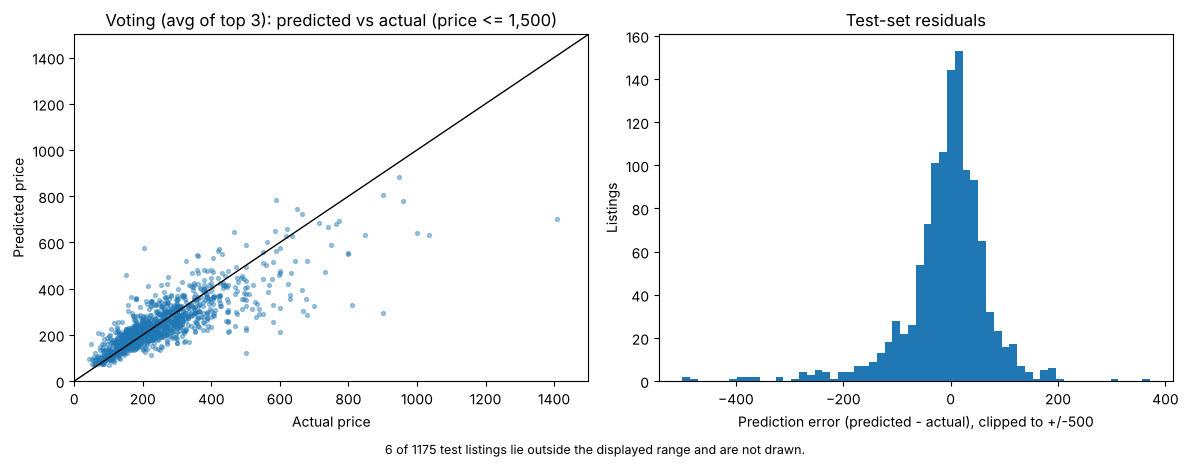

In [25]:
DISPLAY_MAX = 1_500   # display range only; metrics above use every listing
mask = test_mask_below_cap & (y_test.to_numpy() <= DISPLAY_MAX)
err = final_pred - y_test.to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test[mask], final_pred[mask], s=8, alpha=0.4)
axes[0].plot([0, DISPLAY_MAX], [0, DISPLAY_MAX], color="black", lw=1)
axes[0].set(xlabel="Actual price", ylabel="Predicted price", xlim=(0, DISPLAY_MAX), ylim=(0, DISPLAY_MAX),
            title=f"{best_name}: predicted vs actual (price <= {DISPLAY_MAX:,})")
axes[1].hist(np.clip(err[mask], -500, 500), bins=60)
axes[1].set(xlabel="Prediction error (predicted - actual), clipped to +/-500", ylabel="Listings", title="Test-set residuals")
fig.text(0.5, -0.02, f"{(~mask).sum()} of {len(y_test)} test listings lie outside the displayed range and are not drawn.", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "final_model_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

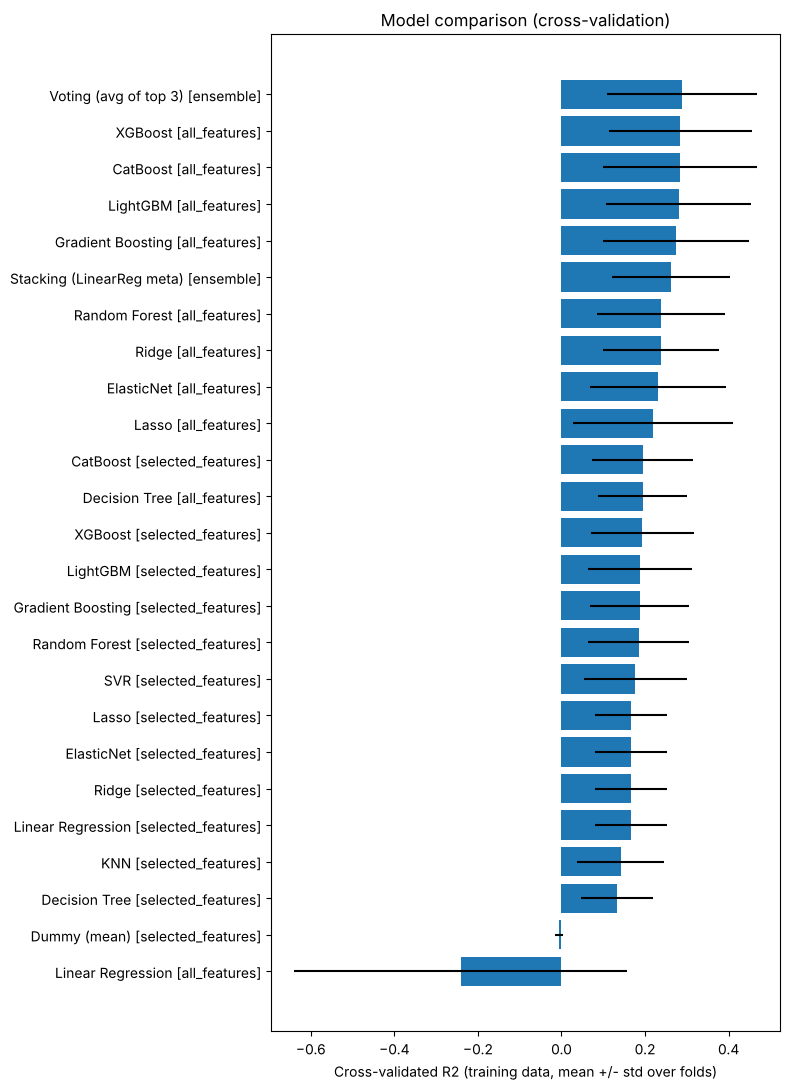

In [26]:
order = cv_results.sort_values("cv_r2_mean")
fig, ax = plt.subplots(figsize=(8, 0.4 * len(order) + 1))
ax.barh(order["model"] + " [" + order["feature_set"] + "]", order["cv_r2_mean"], xerr=order["cv_r2_std"])
ax.set(xlabel="Cross-validated R2 (training data, mean +/- std over folds)", title="Model comparison (cross-validation)")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "cv_model_comparison.png", dpi=150)
plt.show()

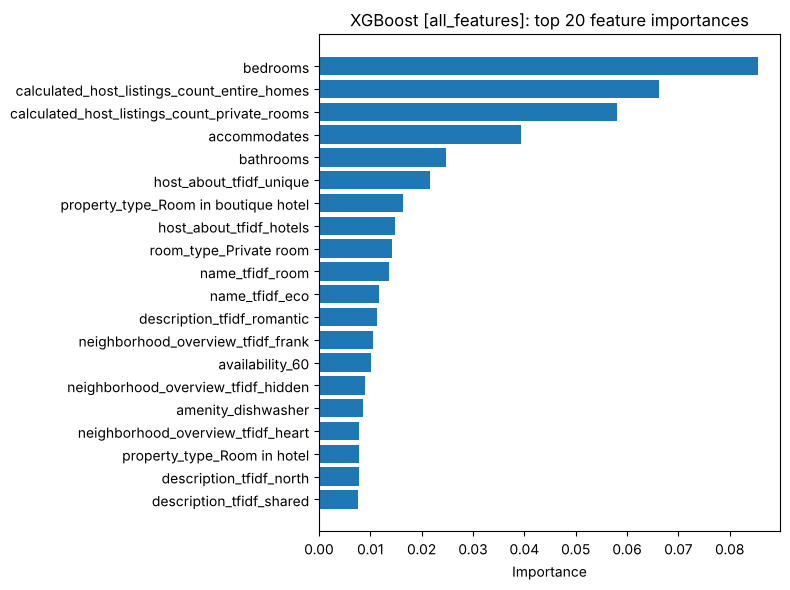

In [27]:
# Feature importance of the best tree-based single model (by CV), if available.
tree_models = ["XGBoost", "LightGBM", "CatBoost", "Random Forest", "Gradient Boosting", "Decision Tree"]
tree_rows = cv_results[cv_results["model"].isin(tree_models)]
t_name, t_fs = tree_rows.iloc[0]["model"], tree_rows.iloc[0]["feature_set"]
inner = FITTED[(t_name, t_fs)].regressor_.named_steps["model"]
imp = pd.Series(np.asarray(inner.feature_importances_), index=FEATURE_SETS[t_fs][0].columns)
inverse_map = {v: k for k, v in mapping.items()}
top = imp.sort_values(ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([inverse_map[i] for i in top.index], top.values)
ax.set(title=f"{t_name} [{t_fs}]: top 20 feature importances", xlabel="Importance")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "feature_importance.png", dpi=150)
plt.show()

## 13. Summary generated from the results above

In [28]:
top_cv = cv_results.iloc[0]
sel_vs_all = (results[results["feature_set"].isin(["all_features", "selected_features"])]
              .pivot(index="model", columns="feature_set", values="cv_r2_mean"))
print(f"Best cross-validated configuration: {top_cv['model']} on {top_cv['feature_set']} "
      f"(CV R2 = {top_cv['cv_r2_mean']:.4f} +/- {top_cv['cv_r2_std']:.4f}).")
print(f"Its held-out test R2 is {final['r2']:.4f} on all {len(y_test)} test listings and "
      f"{final_below['r2']:.4f} on the {test_mask_below_cap.sum()} listings below {PRICE_CAP:,}.")
print(f"{n_test_cap} test listing(s) have price >= {PRICE_CAP:,}; {n_train_cap} such listing(s) were excluded from training.")
print("\nCross-validated R2 by feature set:")
print(sel_vs_all.round(4).to_string())

Best cross-validated configuration: Voting (avg of top 3) on ensemble (CV R2 = 0.2878 +/- 0.1795).
Its held-out test R2 is -0.0015 on all 1175 test listings and 0.2836 on the 1173 listings below 30,000.
2 test listing(s) have price >= 30,000; 5 such listing(s) were excluded from training.

Cross-validated R2 by feature set:
feature_set        all_features  selected_features
model                                             
CatBoost                 0.2833             0.1945
Decision Tree            0.1943             0.1321
Dummy (mean)                NaN            -0.0065
ElasticNet               0.2305             0.1657
Gradient Boosting        0.2737             0.1877
KNN                         NaN             0.1414
Lasso                    0.2189             0.1657
LightGBM                 0.2802             0.1884
Linear Regression       -0.2409             0.1656
Random Forest            0.2377             0.1845
Ridge                    0.2375             0.1656
SVR        